# Taak 7: student fitten op de MACE-dataset

De student is dezelfde geshifte LJ-som over de 424 roosteratomen als in taak 2 (`energy_fast`), maar met de acht **paar**parameters vrij: (ε, σ) voor CH4–Zn, CH4–O, CH4–C en CH4–H. Functies in `src/fit.py`.

**Parametrisatie.** De optimizer werkt op één platte vector van acht getallen:

```
params = [eps_Zn, eps_O, eps_C, eps_H, sigma_Zn, sigma_O, sigma_C, sigma_H]   # paarwaarden met CH4, K en A
```

Gekozen: direct de paarwaarden, niet de elementwaarden met Lorentz-Berthelot erachter. Beide zijn één-op-één, maar met paarwaarden zijn de grenzen voor de optimizer rechtstreeks fysisch, zijn de startwaarden de baseline-paren uit taak 2, en zijn de gefitte getallen meteen wat in de README komt. Van acht getallen naar de twee arrays van lengte 424: elk roosteratoom heeft een elementindex (Zn 0, O 1, C 2, H 3), en `params[0:4][element_index]` pakt voor elk atoom zijn ε.

**Waarop fitten?** Kleinste kwadraten op E weegt elk punt gelijk, maar Widom en GCMC wegen elk punt met exp(−E/T). Daarom twee fits: naïef (ongewogen) en gewogen met w = exp(−E_MACE/T_w), T_w = 1000 K (afgevlakt, zodat niet alleen de 71 diepste punten tellen).

In [1]:
%load_ext autoreload
%autoreload 2
import sys
sys.path.insert(0, "../src")
import time
import numpy as np
import matplotlib.pyplot as plt
from energy import load_framework, load_force_field
from widom import widom, rho_framework, henry_coefficient
from gcmc import CH4_EPS, CH4_SIGMA
from fit import (ELEMENTS, PARAM_NAMES, element_indices, baseline_params, params_to_pairs,
                 student_energies, residuals, boltzmann_weights, fit_student)

In [2]:
positions, symbols, L, masses = load_framework("../data/IRMOF-1.cif")
lj_params = load_force_field("../data/force_field/generic_dreiding_uff_mixing_rules.def")
rho_fw = rho_framework(masses, L)
T = 298.0
K_TO_KJMOL = 1 / 120.27

element_index = element_indices(symbols)
params_baseline = baseline_params(lj_params, (CH4_EPS, CH4_SIGMA))
print("params_baseline =", dict(zip(PARAM_NAMES, params_baseline.round(3))))

data = np.genfromtxt("../data/mace_dataset_irmof1_ch4.csv", delimiter=",", names=True)
dataset_positions = np.column_stack([data["x"], data["y"], data["z"]])
E_base = data["E_baseline_K"]
E_mace = data["E_mace_K"]
print(dataset_positions.shape, "posities")

params_baseline = {'eps_Zn': np.float64(99.45), 'eps_O': np.float64(87.367), 'eps_C': np.float64(87.093), 'eps_H': np.float64(34.819), 'sigma_Zn': np.float64(3.091), 'sigma_O': np.float64(3.377), 'sigma_C': np.float64(3.596), 'sigma_H': np.float64(3.283)}
(4000, 3) posities


/Users/kasperhuysentruyt/Documents/leven /Cusp/cusp-mlff-gcmc/.venv/lib/python3.14/site-packages/ase/io/cif.py:411: UserWarning: crystal system 'cubic' is not interpreted for space group Spacegroup(225, setting=1). This may result in wrong setting!
  warnings.warn(


## Test

Met `params_baseline` moet `student_energies` de kolom `E_baseline_K` teruggeven (zo is die kolom gemaakt). De posities staan met zes decimalen in de CSV; op de steile afstotende wand (E ≈ 8000 K) geeft een verschuiving van 1e-6 Å al 0,03 K verschil, dus `atol=0.1`.

In [3]:
t0 = time.time()
E_check = student_energies(params_baseline, dataset_positions, positions, element_index, L)
dt = time.time() - t0
assert np.allclose(E_check, E_base, atol=0.1), np.abs(E_check - E_base).max()
print(f"test ok, 1 aanroep met {len(E_check)} posities: {dt:.2f} s")
print(f"startkost (baseline): {0.5 * np.sum((E_base - E_mace) ** 2):.3e}, RMS {np.sqrt(np.mean((E_base - E_mace) ** 2)):.0f} K")

test ok, 1 aanroep met 4000 posities: 0.14 s
startkost (baseline): 4.561e+09, RMS 1510 K


## Fit 1: naïef (ongewogen) en fit 2: gewogen

In [4]:
t0 = time.time()
res_naive = fit_student(params_baseline, dataset_positions, positions, element_index, L, E_mace)
params_naive = res_naive.x
print(f"naief  : nfev {res_naive.nfev}, {res_naive.message}, {time.time() - t0:.0f} s")

T_w = 1000.0
weights = boltzmann_weights(E_mace, T_w)
t0 = time.time()
res_weighted = fit_student(params_baseline, dataset_positions, positions, element_index, L, E_mace, weights)
params_weighted = res_weighted.x
print(f"gewogen: nfev {res_weighted.nfev}, {res_weighted.message}, {time.time() - t0:.0f} s")

print()
print(f"{'parameter':10s} {'baseline':>9s} {'naief':>9s} {'gewogen':>9s}")
for name, b, n, w in zip(PARAM_NAMES, params_baseline, params_naive, params_weighted):
    print(f"{name:10s} {b:9.3f} {n:9.3f} {w:9.3f}")

naief  : nfev 62, `ftol` termination condition is satisfied., 71 s


gewogen: nfev 36, `ftol` termination condition is satisfied., 44 s

parameter   baseline     naief   gewogen
eps_Zn        99.450    67.819   108.889
eps_O         87.367   358.766   450.987
eps_C         87.093    99.313    96.503
eps_H         34.819     0.100     0.100
sigma_Zn       3.091     3.728     3.916
sigma_O        3.377     2.974     2.934
sigma_C        3.596     3.474     3.443
sigma_H        3.283     4.350     4.243


In [5]:
E_naive = student_energies(params_naive, dataset_positions, positions, element_index, L)
E_weighted = student_energies(params_weighted, dataset_positions, positions, element_index, L)

attractive = E_base < 0
deep = E_mace * K_TO_KJMOL < -20
models = {"baseline": E_base, "student naief": E_naive, "student gewogen": E_weighted}
print(f"{'':16s} {'<exp(-E/T)>':>12s} {'RMS alle [K]':>13s} {'RMS attractief':>15s} {'RMS diep (<-20)':>16s} {'min [kJ/mol]':>13s}")
for name, E in models.items():
    r = E - E_mace
    print(f"{name:16s} {np.mean(np.exp(-E / T)):12.1f} {np.sqrt(np.mean(r ** 2)):13.0f} {np.sqrt(np.mean(r[attractive] ** 2)):15.0f} "
          f"{np.sqrt(np.mean(r[deep] ** 2)):16.0f} {E.min() * K_TO_KJMOL:13.1f}")
print(f"{'MACE':16s} {np.mean(np.exp(-E_mace / T)):12.1f} {'':>13s} {'':>15s} {'':>16s} {E_mace.min() * K_TO_KJMOL:13.1f}")
print(f"\n(aantal punten: {len(E_mace)} totaal, {attractive.sum()} attractief, {deep.sum()} diep)")

                  <exp(-E/T)>  RMS alle [K]  RMS attractief  RMS diep (<-20)  min [kJ/mol]
baseline                 10.2          1510             462             1539         -13.9
student naief           118.4           479             218              531         -25.6
student gewogen         310.8           624             216              289         -26.8
MACE                    378.9                                                        -29.9

(aantal punten: 4000 totaal, 3291 attractief, 71 diep)


## Pariteitsplot en residuen

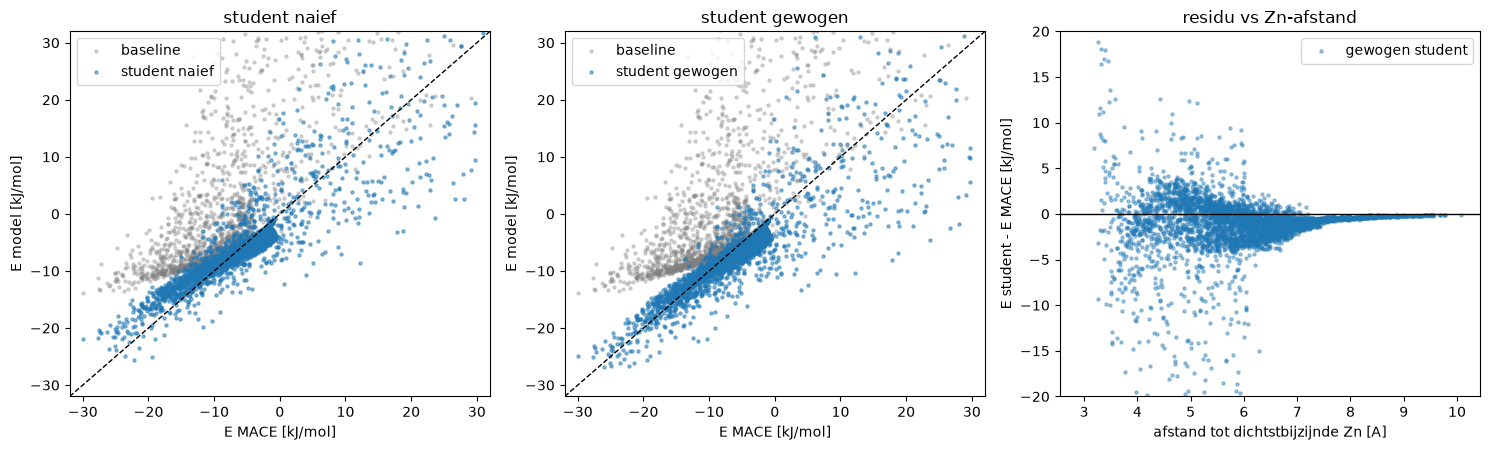

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))
lim = [-32, 32]
for ax, (name, E) in zip(axes[:2], [("student naief", E_naive), ("student gewogen", E_weighted)]):
    ax.scatter(E_mace * K_TO_KJMOL, E_base * K_TO_KJMOL, s=5, alpha=0.3, color="gray", label="baseline")
    ax.scatter(E_mace * K_TO_KJMOL, E * K_TO_KJMOL, s=5, alpha=0.5, label=name)
    ax.plot(lim, lim, "k--", lw=1)
    ax.set_xlim(lim); ax.set_ylim(lim)
    ax.set_xlabel("E MACE [kJ/mol]"); ax.set_ylabel("E model [kJ/mol]")
    ax.set_title(name); ax.legend(loc="upper left")

# residu tegen afstand tot dichtstbijzijnde Zn
from energy import distances_to_framework
zn_positions = positions[np.array(symbols) == "Zn"]
d_zn = np.array([distances_to_framework(zn_positions, p, L).min() for p in dataset_positions])
ax = axes[2]
ax.scatter(d_zn, (E_weighted - E_mace) * K_TO_KJMOL, s=5, alpha=0.4, label="gewogen student")
ax.axhline(0, color="k", lw=1)
ax.set_ylim(-20, 20)
ax.set_xlabel("afstand tot dichtstbijzijnde Zn [A]"); ax.set_ylabel("E student - E MACE [kJ/mol]")
ax.set_title("residu vs Zn-afstand"); ax.legend()
fig.tight_layout()
fig.savefig("../results/student_parity.png", dpi=150)

## K_H: baseline, student en MACE naast elkaar

Student en baseline via Widom met 100.000 verse inserties (seed 100, zoals in notebook 03). MACE via Widom rechtstreeks op de dataset (notebook 06; overlaps tellen als exp(−E/T) = 0).

In [7]:
def widom_K_H(params, seed=100, N=100_000):
    eps_pair, sigma_pair = params_to_pairs(params, element_index)
    rng = np.random.default_rng(seed)
    bm, sem = widom(N, T, positions, eps_pair, sigma_pair, L, rng)
    return bm, sem, henry_coefficient(bm, T, rho_fw), henry_coefficient(sem, T, rho_fw)

K_H_mace, K_H_mace_sem = 1.442e-4, 0.20e-4   # notebook 06
rows = [("baseline DREIDING/UFF", *widom_K_H(params_baseline)),
        ("student naief", *widom_K_H(params_naive)),
        ("student gewogen", *widom_K_H(params_weighted))]
print(f"{'model':24s} {'<exp(-U/T)>':>16s} {'K_H [mol/kg/Pa]':>22s} {'x baseline':>11s} {'/ MACE':>7s}")
K_H_base = rows[0][3]
for name, bm, sem, kh, kh_sem in rows:
    print(f"{name:24s} {bm:9.3f} +- {sem:5.3f} {kh:11.3e} +- {kh_sem:8.1e} {kh / K_H_base:11.1f} {kh / K_H_mace:7.2f}")
print(f"{'MACE-MP-0 + D3':24s} {'':>16s} {K_H_mace:11.3e} +- {K_H_mace_sem:8.1e} {K_H_mace / K_H_base:11.1f} {'1.00':>7s}")
np.savetxt("../results/student_params.csv", np.column_stack([params_baseline, params_naive, params_weighted]),
           delimiter=",", header="baseline,naive,weighted  (rows: " + ",".join(PARAM_NAMES) + ")", comments="# ", fmt="%.4f")

model                         <exp(-U/T)>        K_H [mol/kg/Pa]  x baseline  / MACE
baseline DREIDING/UFF        5.634 +- 0.027   3.832e-06 +-  1.8e-08         1.0    0.03
student naief               52.746 +- 1.439   3.588e-05 +-  9.8e-07         9.4    0.25
student gewogen            133.578 +- 3.362   9.087e-05 +-  2.3e-06        23.7    0.63
MACE-MP-0 + D3                              1.442e-04 +-  2.0e-05        37.6    1.00


## Bevindingen

- **De gewogen fit is de goede student.** Op alle punten samen is hij slechter dan de naïeve fit (RMS hoger), maar op de diepe putten, die ⟨exp(−E/T)⟩ en dus K_H bepalen, is hij bijna twee keer beter. Dat is het effect van de weging: de naïeve kost zat voor 77% in 325 afstotende punten die GCMC nooit bezoekt.
- **K_H**: baseline 3,8e-6, gewogen student ≈ 9e-5, MACE 1,4e-4 mol/kg/Pa. De student dicht op log-schaal het grootste deel van de kloof (student/MACE ≈ 0,6).
- **ε_H loopt naar de ondergrens** in beide fits. De optimizer schakelt waterstof uit en compenseert met een veel diepere en kleinere O-put (ε_O ≈ 4× baseline, σ_O kleiner). De student heeft effectief zes parameters; ε en σ van één paar zijn sterk gecorreleerd en H draagt weinig bij.
- **Op de dataset scoort de student beter dan op verse Widom-punten** (verhouding student/MACE 0,82 op de dataset, 0,63 via Widom). Dat is overfitting in de zwakke zin: de weging laat 71 diepe punten domineren, en de acht parameters passen zich deels aan die specifieke punten aan. Een grotere dataset of een gerichte bemonstering van de diepe gebieden (bv. actief leren op grote residuen) is de voor de hand liggende volgende stap.
- **Waar de student faalt**: zie de residu-plot tegen de Zn-afstand. Verder dan 7 Å van een Zn is de student vrijwel exact; binnen 3 tot 6 Å, rond de Zn4O-hoeken waar MACE de diepste putten heeft, spreidt het residu tot ±20 kJ/mol in beide richtingen. Eén LJ-bol per paar kan de vorm en de oriëntatie-afhankelijkheid van de MACE-put daar niet volgen (de dataset heeft all-atom CH4, de student ziet alleen het C-atoom).
- Kost: één fit ≈ 1 minuut (36 tot 62 functie-evaluaties, elk met acht extra aanroepen voor de numerieke Jacobiaan), vectoriseren was niet nodig.